# MenoPhenotype — Notebook 2: Data Quality Check

This notebook performs data cleaning on the raw SWAN Baseline and Screener files:
- Standardizes missing value sentinel strings (`'Missing'`, `'Do not know'`) to `NaN`.
- Identifies and removes structurally blank columns (follow-up questions with high skip rates) and zero-variance features (e.g., constant hormone therapy flags).
- Filters out records with excessive missingness across core symptom items.
- Exports cleaned baseline and screener tables along with shared column metadata to `artifacts/`.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
SENTINELS = ['Missing', 'Do not know', 'Do Not Know']   # text codes indicating missing responses


## A. SWAN Baseline (ICPSR 28762)
### A.1 Load and recode text sentinels

In [2]:
raw = pd.read_csv('data/swan_baseline_28762.csv', low_memory=False).set_index('SWANID')
df = raw.copy()
obj_cols = df.select_dtypes(exclude='number').columns
n_sent = df[obj_cols].isin(SENTINELS).sum().sum()
df[obj_cols] = df[obj_cols].replace(SENTINELS, np.nan)
print(f"Loaded {raw.shape[0]:,} x {raw.shape[1]} | sentinel cells converted to NaN: {n_sent:,}")
print("Duplicate rows (all columns):", raw.duplicated().sum(), "| duplicate SWANIDs:", raw.index.duplicated().sum())


Loaded 3,302 x 740 | sentinel cells converted to NaN: 14,396
Duplicate rows (all columns): 0 | duplicate SWANIDs: 0


### A.2 Feature groupings

Group candidate columns by domain (symptoms, depression, hormones, anthropometrics) for systematic quality checks and downstream modeling.


In [3]:
SYMPTOMS = {
    'vasomotor': ['HOTFLAS0', 'NITESWE0', 'COLDSWE0'],
    'psychological': ['FEELBLU0', 'IRRITAB0', 'NRVOUS0', 'FORGET0', 'MOODCHG0', 'FEARFULA0'],
    'somatic': ['STIFF0', 'HDACHE0', 'VAGINDR0', 'HARTRAC0', 'DIZZY0', 'LEAKURI0'],
    'sleep': ['TRBLSLE0', 'WAKEUP0', 'WAKEARL0'],
}
SYMP_COLS = sum(SYMPTOMS.values(), [])
CESD_COLS = ['BOTHER0','APPETIT0','BLUES0','GOOD0','KEEPMIN0','DEPRESS0','EFFORT0','HOPEFUL0',
             'FAILURE0','FEARFUL0','RESTLES0','HAPPY0','TALKLES0','LONELY0']
HORM_COLS = ['FSH0', 'E2AVE0', 'T0', 'TSH0', 'SHBG0', 'DHAS0']
FOLLOWUP  = ['FLASHPH0', 'FLASHEB0', 'FLASHEM0']          # asked only if the woman reported hot flashes
HT_COLS   = ['HORMCRE0', 'HORMPIL0', 'ESTRPTC0', 'BCP0']   # hormone-therapy / contraceptive use flags
ANTHRO    = ['BMI0', 'WAIST0', 'HIP0']
OTHER     = ['AGE0', 'SPORTS0']
POSTHOC   = ['STATUS0', 'RACE']                            # never used as clustering features

cand = SYMP_COLS + CESD_COLS + HORM_COLS + FOLLOWUP + ANTHRO + OTHER
miss = df[cand].isna().mean().mul(100).sort_values(ascending=False)
print("Missingness (%) INCLUDING sentinel codes, candidate columns only:")
print(miss.round(1).head(12).to_string())
print(f"\nExcluding the 3 hot-flash follow-ups, worst candidate column: {miss.drop(FOLLOWUP).max():.1f}% missing")


Missingness (%) INCLUDING sentinel codes, candidate columns only:
FLASHEB0    75.0
FLASHEM0    75.0
FLASHPH0    73.8
COLDSWE0     2.9
BMI0         1.3
HIP0         1.3
TSH0         1.2
WAIST0       1.1
SPORTS0      1.0
VAGINDR0     0.8
DIZZY0       0.6
NRVOUS0      0.6

Excluding the 3 hot-flash follow-ups, worst candidate column: 2.9% missing


### A.3 Structural missingness and uninformative columns

- `FLASHPH0`, `FLASHEB0`, and `FLASHEM0` are conditional follow-ups asked only when a participant reported hot flashes. Because they have high structural missingness and are largely redundant with `HOTFLAS0`, they are omitted from the feature matrix.
- The four hormone-therapy variables are effectively invariant in this cohort (all recorded answers are "No"), providing zero variance.

Both subsets are dropped at the column level.


In [4]:
asked = df['HOTFLAS0'].notna() & (df['HOTFLAS0'] != 'Not At All')
print("Women reporting any hot flashes:", asked.sum(), "| FLASHPH0 answered:", df['FLASHPH0'].notna().sum())
for c in HT_COLS:
    print(f"{c}: {df[c].value_counts(dropna=False).to_dict()}")
print("\nDropping columns with structural missingness or zero variance:", FOLLOWUP + HT_COLS)
df = df.drop(columns=FOLLOWUP + HT_COLS)


Women reporting any hot flashes: 878 | FLASHPH0 answered: 864
HORMCRE0: {'No': 3290, nan: 12}
HORMPIL0: {'No': 3291, nan: 11}
ESTRPTC0: {'No': 3291, nan: 11}
BCP0: {'No': 3291, nan: 11}

Decision: drop ['FLASHPH0', 'FLASHEB0', 'FLASHEM0', 'HORMCRE0', 'HORMPIL0', 'ESTRPTC0', 'BCP0'] as columns (structural missingness / zero variance).


### A.4 Row-level symptom missingness

Participants missing the majority of symptom responses cannot be reliably phenotyped without distorting cluster centroids toward the imputation median. We check row-level completion and remove records with >30% missing symptom items.


Rows with >=1 symptom missing: 184 | >30% of the 18 symptoms missing: 12 | all 18 missing: 7


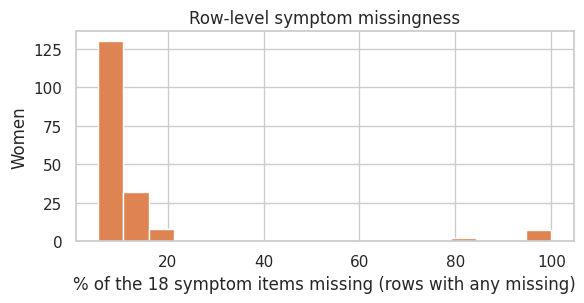


Decision: drop 12 women with >30% symptoms missing -> n = 3,290


In [5]:
F5 = {'Not At All': 0, '1-5 Days': 1, '6-8 Days': 2, '9-13 Days': 3, 'Every Day': 4}
SLP = {'No, Not In The Past 2 Wks': 0, 'Yes, < Once A Wk': 1, 'Yes, 1-2 Times/Wk': 2,
       'Yes, 3-4 Times/Wk': 3, 'Yes, 5 or More Times/Wk': 4}
sym_check = pd.DataFrame({c: df[c].map(SLP if c in SYMPTOMS['sleep'] else F5) for c in SYMP_COLS})
row_miss = sym_check.isna().mean(axis=1)

print("Rows with >=1 symptom missing:", (row_miss > 0).sum(),
      "| >30% of the 18 symptoms missing:", (row_miss > 0.30).sum(),
      "| all 18 missing:", (row_miss == 1).sum())
plt.figure(figsize=(6, 3.2))
plt.hist(row_miss[row_miss > 0] * 100, bins=18, color='#DD8452', edgecolor='white')
plt.xlabel('% of the 18 symptom items missing (rows with any missing)'); plt.ylabel('Women')
plt.title('Row-level symptom missingness'); plt.tight_layout(); plt.show()

drop_ids = row_miss.index[row_miss > 0.30]
df = df.loc[df.index.difference(drop_ids)]
print(f"\nDropping {len(drop_ids)} records with >30% symptoms missing -> remaining n = {len(df):,}")


### A.5 Save cleaned baseline data


In [6]:
df.to_csv(ART / 'baseline_clean.csv')
print("Saved artifacts/baseline_clean.csv", df.shape)


Saved artifacts/baseline_clean.csv (3290, 733)


## B. SWAN Screener (ICPSR 04368)
### B.1 Load and inspect screener data


In [7]:
scr_raw = pd.read_csv('data/swan_screener_04368.csv', low_memory=False).set_index('SWANID')
scr = scr_raw.copy()
oc = scr.select_dtypes(exclude='number').columns
n_sent_scr = scr[oc].isin(SENTINELS).sum().sum()
scr[oc] = scr[oc].replace(SENTINELS, np.nan)

SCR_SYMP = ['HOTFLASH','NISWEAT','STIFF','HEADACH','FORGET','TENSE','DEPRESS','DRYNESS','IRRITAB','HEARTBO','URINE']
print(f"Loaded {scr_raw.shape[0]:,} x {scr_raw.shape[1]} | sentinel cells converted to NaN: {n_sent_scr:,}")
print("Rows identical on every column:", int(scr_raw.duplicated().sum()), "| duplicate SWANIDs:", int(scr_raw.index.duplicated().sum()))
print("\nSymptom-item missingness (%):"); print((scr[SCR_SYMP].isna().mean() * 100).round(2).to_string())


Loaded 16,142 x 110 | sentinel cells converted to NaN: 153
Rows identical on every column: 4 | duplicate SWANIDs: 0

Symptom-item missingness (%):
HOTFLASH    0.85
NISWEAT     0.56
STIFF       0.45
HEADACH     0.41
FORGET      0.55
TENSE       0.50
DEPRESS     0.46
DRYNESS     1.29
IRRITAB     0.55
HEARTBO     0.49
URINE       1.27


**Observations:**
- Rows with identical symptom responses have unique `SWANID` values, representing distinct individuals with identical response profiles rather than duplicate entries.
- Symptom-level missingness is below 1%, so row pruning is unnecessary here. Subsequent cohort filtering (such as removing overlap with Baseline) will be handled during validation setup.


In [8]:
scr.to_csv(ART / 'screener_clean.csv')
print("Saved artifacts/screener_clean.csv", scr.shape)


Saved artifacts/screener_clean.csv (16142, 110)


## C. Save metadata


In [9]:
meta = {
    'SYMPTOMS': SYMPTOMS, 'SYMP_COLS': SYMP_COLS, 'CESD_COLS': CESD_COLS, 'HORM_COLS': HORM_COLS,
    'ANTHRO': ANTHRO, 'OTHER': OTHER, 'POSTHOC': POSTHOC, 'SCR_SYMP': SCR_SYMP,
    'dropped_baseline_columns': FOLLOWUP + HT_COLS, 'dropped_baseline_rows_n': int(len(drop_ids)),
    'sentinels': SENTINELS,
}
json.dump(meta, open(ART / 'quality_meta.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))


{
  "SYMPTOMS": {
    "vasomotor": [
      "HOTFLAS0",
      "NITESWE0",
      "COLDSWE0"
    ],
    "psychological": [
      "FEELBLU0",
      "IRRITAB0",
      "NRVOUS0",
      "FORGET0",
      "MOODCHG0",
      "FEARFULA0"
    ],
    "somatic": [
      "STIFF0",
      "HDACHE0",
      "VAGINDR0",
      "HARTRAC0",
      "DIZZY0",
      "LEAKURI0"
    ],
    "sleep": [
      "TRBLSLE0",
      "WAKEUP0",
      "WAKEARL0"
    ]
  },
  "SYMP_COLS": [
    "HOTFLAS0",
    "NITESWE0",
    "COLDSWE0",
    "FEELBLU0",
    "IRRITAB0",
    "NRVOUS0",
    "FORGET0",
    "MOODCHG0",
    "FEARFULA0",
    "STIFF0",
    "HDACHE0",
    "VAGINDR0",
    "HARTRAC0",
    "DIZZY0",
    "LEAKURI0",
    "TRBLSLE0",
    "WAKEUP0",
    "WAKEARL0"
  ],
  "CESD_COLS": [
    "BOTHER0",
    "APPETIT0",
    "BLUES0",
    "GOOD0",
    "KEEPMIN0",
    "DEPRESS0",
    "EFFORT0",
    "HOPEFUL0",
    "FAILURE0",
    "FEARFUL0",
    "RESTLES0",
    "HAPPY0",
    "TALKLES0",
    "LONELY0"
  ],
  "HORM_COLS": [
    "FSH0

### Summary of Cleaning Steps

- **Sentinel values:** Replaced `'Missing'` and `'Do not know'` with `NaN` across both datasets.
- **Dropped columns:** Removed 3 conditional hot-flash follow-up items (structural missingness) and 4 invariant hormone-therapy flags.
- **Row filtering:** Excluded participants with >30% missing responses across the 18 baseline symptom items.
- **Outputs:** Saved cleaned tables and metadata dictionary to `artifacts/`. Next step is feature engineering in Notebook 03.
